In [10]:
from sklearn.cluster import KMeans
from sklearn import metrics
from sklearn import preprocessing
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

In [11]:
Wcs_data = pd.read_csv('data/Wholesale customers data.csv')
Wcs_data.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [12]:
features = Wcs_data.columns[2:]
Wcs_data = Wcs_data[features]
Wcs_data.head()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,12669,9656,7561,214,2674,1338
1,7057,9810,9568,1762,3293,1776
2,6353,8808,7684,2405,3516,7844
3,13265,1196,4221,6404,507,1788
4,22615,5410,7198,3915,1777,5185


In [13]:
X = preprocessing.StandardScaler().fit_transform(Wcs_data)
X.shape

(440, 6)

In [14]:
ks = range(2, 11)
inertia, silhouette, ch_score = [], [], []

for k in ks:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = kmeans.fit_predict(X)
    inertia.append(kmeans.inertia_)
    silhouette.append(metrics.silhouette_score(X, labels))
    ch_score.append(metrics.calinski_harabasz_score(X, labels))

score_df = pd.DataFrame({
    'k': list(ks),
    'inertia': inertia,
    'silhouette': silhouette,
    'CH': ch_score
}).set_index('k')
score_df.round(4)

,inertia,silhouette,CH
k,,,
2,1956.1243,0.5472,153.1281
3,1608.4311,0.5483,140.1352
4,1317.8384,0.3485,145.8101
5,1058.7713,0.3690,162.4134
6,915.7413,0.3782,163.4366
7,825.4003,0.3343,158.6547
8,737.3862,0.3201,159.2360
9,661.4496,0.3090,161.1527
10,605.9151,0.3112,160.3922


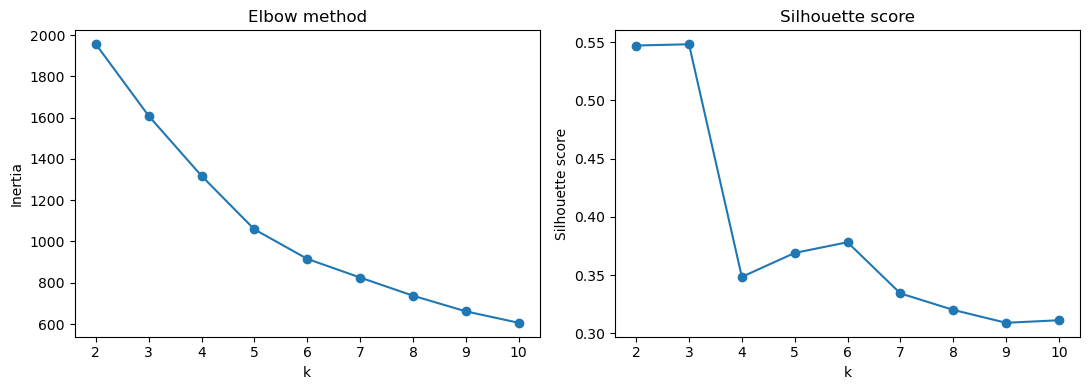

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(score_df.index, score_df['inertia'], 'o-')
axes[0].set_xlabel('k')
axes[0].set_ylabel('Inertia')
axes[0].set_title('Elbow method')

axes[1].plot(score_df.index, score_df['silhouette'], 'o-')
axes[1].set_xlabel('k')
axes[1].set_ylabel('Silhouette score')
axes[1].set_title('Silhouette score')

plt.tight_layout()
plt.show()

In [16]:
k = 3
kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
Wcs_data['Cluster'] = kmeans.fit_predict(X)
Wcs_data['Cluster'].value_counts().sort_index()

Cluster
0     45
1    393
2      2
Name: count, dtype: int64

In [17]:
profile = Wcs_data.groupby('Cluster')[list(features)].mean().round(1)
profile

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Cluster,,,,,,
0,10440.9,19386.4,28656.1,2190.2,13327.8,2374.2
1,12062.9,4115.1,5535.0,2940.7,1696.2,1299.1
2,34782.0,30367.0,16898.0,48701.5,755.5,26776.0


In [18]:
ratio = (profile / Wcs_data[list(features)].mean()).round(2)
ratio

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Cluster,,,,,,
0,0.87,3.34,3.60,0.71,4.63,1.56
1,1.01,0.71,0.70,0.96,0.59,0.85
2,2.90,5.24,2.13,15.85,0.26,17.56


In [19]:
centers = pd.DataFrame(kmeans.cluster_centers_, columns=features).round(2)
centers

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,-0.12,1.84,2.18,-0.18,2.19,0.30
1,0.00,-0.23,-0.25,-0.03,-0.25,-0.08
2,1.80,3.33,0.94,9.41,-0.45,8.96


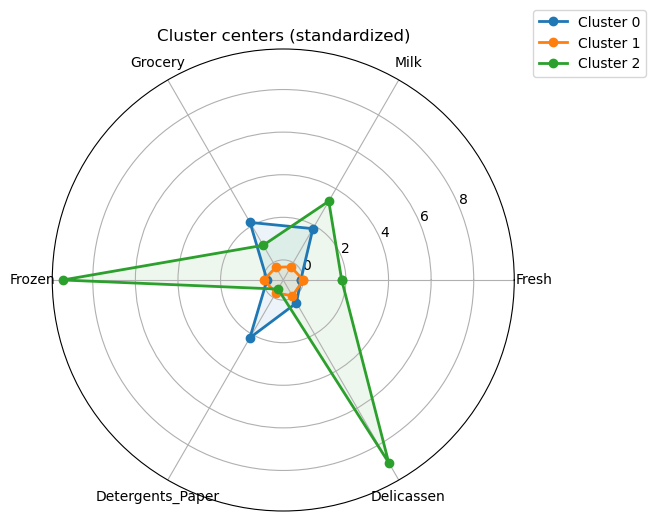

In [20]:
angles = np.linspace(0, 2 * np.pi, len(features), endpoint=False).tolist()
angles += angles[:1]

fig = plt.figure(figsize=(7, 6))
ax = plt.subplot(111, polar=True)

for c in centers.index:
    values = centers.loc[c].tolist()
    values += values[:1]
    ax.plot(angles, values, 'o-', linewidth=2, label=f'Cluster {c}')
    ax.fill(angles, values, alpha=0.08)

ax.set_thetagrids(np.degrees(angles[:-1]), features)
ax.set_title('Cluster centers (standardized)')
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.show()

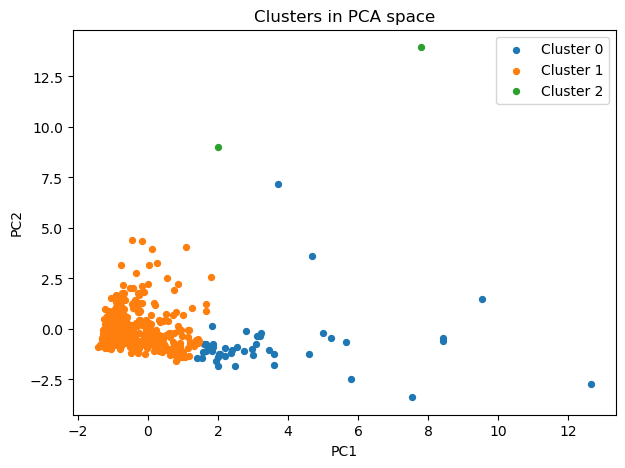

In [21]:
X_pca = PCA(n_components=2, random_state=42).fit_transform(X)

plt.figure(figsize=(7, 5))
for c in sorted(Wcs_data['Cluster'].unique()):
    plt.scatter(X_pca[Wcs_data['Cluster'] == c, 0],
                X_pca[Wcs_data['Cluster'] == c, 1],
                s=18, label=f'Cluster {c}')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Clusters in PCA space')
plt.legend()
plt.show()

In [22]:
sizes = Wcs_data['Cluster'].value_counts().sort_index()

print('各类客户规模：')
for c in sizes.index:
    print(f'第{c}类：{sizes[c]}户')

print('各特征相对总体平均进货额的比例（大于1表示高于平均）：')
for c in ratio.index:
    high = ratio.loc[c][ratio.loc[c] >= 1.2].sort_values(ascending=False)
    if len(high) > 0:
        desc = '、'.join(f'{name} {value:.1f} 倍' for name, value in high.items())
        print(f'第{c}类：{desc}')
    else:
        print(f'第{c}类：没有明显高于平均水平的特征')

各类客户规模：
第0类：45户
第1类：393户
第2类：2户
各特征相对总体平均进货额的比例（大于1表示高于平均）：
第0类：Detergents_Paper 4.6 倍、Grocery 3.6 倍、Milk 3.3 倍、Delicassen 1.6 倍
第1类：没有明显高于平均水平的特征
第2类：Delicassen 17.6 倍、Frozen 15.8 倍、Milk 5.2 倍、Fresh 2.9 倍、Grocery 2.1 倍


In [25]:
print('分类结果解释：')
print('第0类（45户）：牛奶、杂货和清洁用品的进货额达到平均水平的3至5倍，属于以日用品为主的超市、零售店。')
print('第1类（393户）：只有生鲜接近平均水平，其余各项均偏低，属于采购量较小的小型餐饮店和社区商店。')
print('第2类（2户）：冷冻和熟食的进货额超过平均的15倍，牛奶约为5倍，是体量远超其他客户的超级客户；')
print('\n以上内容纯属个人猜测，毕竟题目里说要对分类结果进行解释（我也不知道是不是这么解释的）')

分类结果解释：
第0类（45户）：牛奶、杂货和清洁用品的进货额达到平均水平的3至5倍，属于以日用品为主的超市、零售店。
第1类（393户）：只有生鲜接近平均水平，其余各项均偏低，属于采购量较小的小型餐饮店和社区商店。
第2类（2户）：冷冻和熟食的进货额超过平均的15倍，牛奶约为5倍，是体量远超其他客户的超级客户；

以上内容纯属个人猜测，毕竟题目里说要对分类结果进行解释（我也不知道是不是这么解释的）
